# `scripts/descriptive_slides.py`

報告 `report/expected_score.typ` 的「上一局與本局的轉移」「連輸、連贏之後的離開」：arena 內的一階 Markov 轉移與連輸、連贏後的離開率。

本 notebook 由 `notebooks/build.py` 從腳本自動產生，內容以腳本為準。

第一次分析報告（描述性分析）投影片用的分組平均與統計圖。不配模型、不做檢定，也不附區間：
同一玩家的對局彼此相依，iid 的區間會誤導，推論留到之後的報告。
期望得分一律用表頭等級分代入 Elo 公式 E = 1 / (1 + 10^(-d/400))，不含 RD，也不含白方優勢。
玩家狀態只看 2014 年的 arena：前瞻驗證期的結果與續下在驗證前不得看。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTE, GRID = "#22262b", "#6b7178", "#e6e6e3"
CLASSES = ["Bullet", "Blitz", "Classical"]
COLOR = dict(zip(CLASSES, [BLUE, ORANGE, AQUA]))
MARK = dict(zip(CLASSES, ["o", "s", "^"]))
T = lambda f: pl.read_csv(f"outputs/tables/{f}.csv")
q = np.log(10) / 400
logit_e = lambda e: np.log(e / (1 - e))

校準的分組平均由 calibration.py 輸出（E 的 0.05 寬分組）；這裡只畫，不重算

In [3]:
cc = T("calibration_curve")

Elo 與 Glicko 的期望得分：公式的圖，不是資料。RD 取新帳號的 350 與新手門檻 110

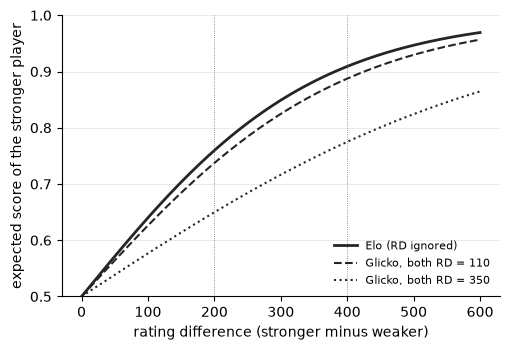

In [4]:
elo = lambda d: 1 / (1 + 10 ** (-d / 400))
fig, ax = plt.subplots(figsize=(5.2, 3.6))
d = np.linspace(0, 600, 200)
ax.plot(d, elo(d), color=INK, lw=2, label="Elo (RD ignored)")
for rdv, ls in [(110, "--"), (350, ":")]:
    g = 1 / np.sqrt(1 + 3 * q**2 * 2 * rdv**2 / np.pi**2)
    ax.plot(d, elo(g * d), color=INK, lw=1.5, ls=ls, label=f"Glicko, both RD = {rdv}")
for dv in [200, 400]:
    ax.axvline(dv, color=MUTE, lw=0.6, ls=":")
ax.set_xlabel("rating difference (stronger minus weaker)")
ax.set_ylabel("expected score of the stronger player")
ax.set_ylim(0.5, 1)
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_elo_glicko.svg")

老手對局各組平均的 S - E。橫軸用分差：E 是分差的單調函數，聽眾讀分差比讀 E 容易

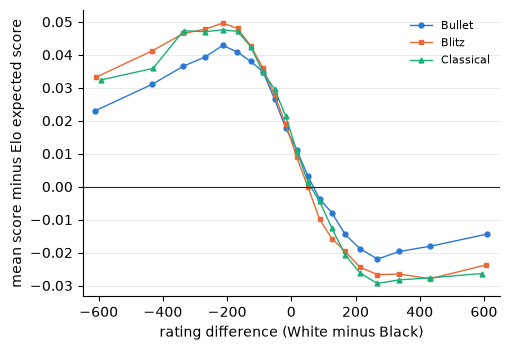

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for tc in CLASSES:
    c = cc.filter(pl.col("speed") == tc, pl.col("stratum_type") == "all", pl.col("n") >= 1000).sort("e_bin")
    ax.plot(logit_e(c["e_mean"]) / q, c["resid_mean"], MARK[tc] + "-", color=COLOR[tc], ms=3.5, lw=1, label=tc)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlim(-650, 650)
ax.set_xlabel("rating difference (White minus Black)")
ax.set_ylabel("mean score minus Elo expected score")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_resid_by_gap.svg")

實際減期望，依雙方中較少的累計局數分三組；新帳號的偏差在曲線兩端最明顯

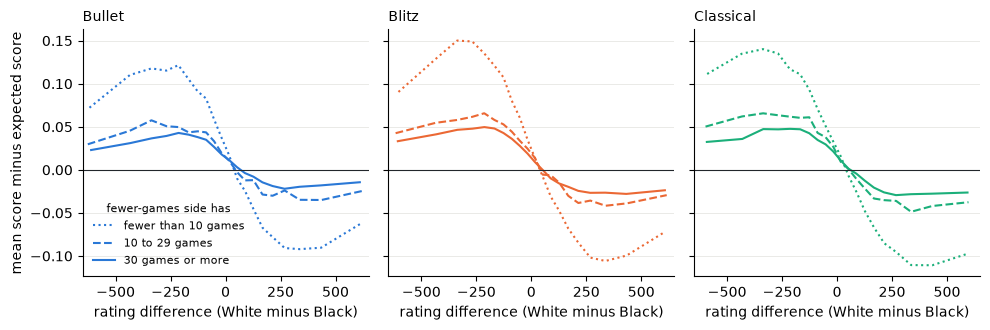

In [6]:
EXP = [("<10", "fewer than 10 games"), ("10-29", "10 to 29 games"), (">=30", "30 games or more")]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, tc in zip(axes, CLASSES):
    for (g, lab), ls in zip(EXP, [":", "--", "-"]):
        c = cc.filter(pl.col("speed") == tc, pl.col("stratum_type") == "experience", pl.col("stratum") == g, pl.col("n") >= 1000).sort("e_bin")
        ax.plot(logit_e(c["e_mean"]) / q, c["resid_mean"], ls, color=COLOR[tc], lw=1.5, label=lab)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(tc, fontsize=10, loc="left")
    ax.set_xlim(-650, 650)
    ax.set_xlabel("rating difference (White minus Black)")
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mean score minus expected score")
axes[0].legend(frameon=False, fontsize=8, title="fewer-games side has", title_fontsize=8)
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_experience.svg")

In [7]:
ext = (
    cc.filter(pl.col("stratum_type").is_in(["all", "experience"]), pl.col("n") >= 1000)
    .group_by("speed", "stratum")
    .agg(resid_max=pl.col("resid_mean").max(), resid_min=pl.col("resid_mean").min())
    .sort("speed", "stratum")
)
print(ext)
ext.write_csv("outputs/tables/descriptive_slides_gap_extremes.csv")

shape: (12, 4)
┌───────────┬─────────┬───────────┬───────────┐
│ speed     ┆ stratum ┆ resid_max ┆ resid_min │
│ ---       ┆ ---     ┆ ---       ┆ ---       │
│ str       ┆ str     ┆ f64       ┆ f64       │
╞═══════════╪═════════╪═══════════╪═══════════╡
│ Blitz     ┆ 10-29   ┆ 0.065694  ┆ -0.041697 │
│ Blitz     ┆ <10     ┆ 0.150098  ┆ -0.105812 │
│ Blitz     ┆ >=30    ┆ 0.049643  ┆ -0.027945 │
│ Blitz     ┆ all     ┆ 0.049643  ┆ -0.027945 │
│ Bullet    ┆ 10-29   ┆ 0.057503  ┆ -0.035007 │
│ …         ┆ …       ┆ …         ┆ …         │
│ Bullet    ┆ all     ┆ 0.042843  ┆ -0.02197  │
│ Classical ┆ 10-29   ┆ 0.065642  ┆ -0.048686 │
│ Classical ┆ <10     ┆ 0.140156  ┆ -0.110792 │
│ Classical ┆ >=30    ┆ 0.047594  ┆ -0.02937  │
│ Classical ┆ all     ┆ 0.047594  ┆ -0.02937  │
└───────────┴─────────┴───────────┴───────────┘


勢均力敵（分差 25 分內）的老手對局：和局率與白方得分隨等級分

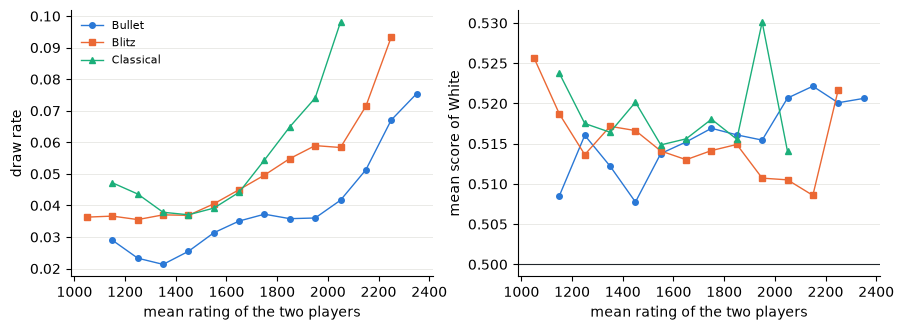

In [8]:
lv = T("calibration_level")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for tc in CLASSES:
    c = lv.filter(pl.col("speed") == tc, pl.col("n") >= 1000)
    axes[0].plot(c["r_bin"], c["draw_rate"], MARK[tc] + "-", color=COLOR[tc], ms=4, lw=1, label=tc)
    axes[1].plot(c["r_bin"], c["white_score"], MARK[tc] + "-", color=COLOR[tc], ms=4, lw=1)
axes[1].axhline(0.5, color=INK, lw=0.8)
axes[0].set_ylabel("draw rate")
axes[1].set_ylabel("mean score of White")
for ax in axes:
    ax.set_xlabel("mean rating of the two players")
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_level.svg")

In [9]:
level = lv.filter(pl.col("n") >= 1000).group_by("speed").agg(
    draw_lo=pl.col("draw_rate").min(), draw_hi=pl.col("draw_rate").max(), white_lo=pl.col("white_score").min(), white_hi=pl.col("white_score").max()
).sort("speed")
print(level)
level.write_csv("outputs/tables/descriptive_slides_level.csv")

shape: (3, 5)
┌───────────┬──────────┬──────────┬──────────┬──────────┐
│ speed     ┆ draw_lo  ┆ draw_hi  ┆ white_lo ┆ white_hi │
│ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str       ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═══════════╪══════════╪══════════╪══════════╪══════════╡
│ Blitz     ┆ 0.035525 ┆ 0.093317 ┆ 0.508579 ┆ 0.525651 │
│ Bullet    ┆ 0.021328 ┆ 0.075391 ┆ 0.507748 ┆ 0.522145 │
│ Classical ┆ 0.037051 ┆ 0.098099 ┆ 0.514045 ┆ 0.53011  │
└───────────┴──────────┴──────────┴──────────┴──────────┘


玩家狀態：同一場 arena 內依開局時間排序；上一局指同一場的前一局

In [10]:
a = (
    pl.scan_parquet("data/processed/player_games.parquet")
    .filter(pl.col("arena"), pl.col("start") < pl.datetime(2015, 1, 1, time_zone="UTC"))
    .select("player", "tournament_id", "start", "speed", "color", "elo", "opp_elo", "score", "tour_left")
    .collect()
    .sort("player", "tournament_id", "start")
    .with_columns(
        k=pl.int_range(1, pl.len() + 1).over("player", "tournament_id"),
        K=pl.len().over("player", "tournament_id"),
        prev=pl.col("score").shift(1).over("player", "tournament_id"),
        run=pl.col("score").rle_id().over("player", "tournament_id"),
    )
    .with_columns(streak=pl.int_range(1, pl.len() + 1).over("player", "tournament_id", "run"))
    .filter(pl.col("elo").is_not_null(), pl.col("opp_elo").is_not_null(), pl.col("score").is_not_null())
    .with_columns(E=1 / (1 + 10 ** (-(pl.col("elo") - pl.col("opp_elo")) / 400)))
    .with_columns(resid=pl.col("score") - pl.col("E"))
)

In [11]:
sample = a.group_by("speed").agg(
    player_games=pl.len(), players=pl.col("player").n_unique(), tournaments=pl.col("tournament_id").n_unique(), with_prev=pl.col("prev").is_not_null().sum()
).sort("speed")
print(sample)
sample.write_csv("outputs/tables/descriptive_slides_arena_sample.csv")

shape: (3, 5)
┌───────────┬──────────────┬─────────┬─────────────┬───────────┐
│ speed     ┆ player_games ┆ players ┆ tournaments ┆ with_prev │
│ ---       ┆ ---          ┆ ---     ┆ ---         ┆ ---       │
│ str       ┆ u32          ┆ u32     ┆ u32         ┆ u32       │
╞═══════════╪══════════════╪═════════╪═════════════╪═══════════╡
│ Blitz     ┆ 1108036      ┆ 19630   ┆ 9788        ┆ 854196    │
│ Bullet    ┆ 822074       ┆ 17737   ┆ 11197       ┆ 701184    │
│ Classical ┆ 67470        ┆ 4446    ┆ 957         ┆ 51549     │
└───────────┴──────────────┴─────────┴─────────────┴───────────┘


一階 Markov 轉移：上一局結果 → 本局結果，只估轉移機率 n_ij / n_i+，不對照任何理論上的期望

In [12]:
R3 = ["loss", "draw", "win"]
markov = (
    a.filter(pl.col("prev").is_not_null())
    .with_columns(
        prev=pl.col("prev").replace_strict({0.0: "loss", 0.5: "draw", 1.0: "win"}),
        cur=pl.col("score").replace_strict({0.0: "loss", 0.5: "draw", 1.0: "win"}),
    )
    .group_by("speed", "prev", "cur")
    .agg(n=pl.len())
    .with_columns(p=pl.col("n") / pl.col("n").sum().over("speed", "prev"))
    .sort("speed", "prev", "cur")
)
print(markov)
markov.write_csv("outputs/tables/descriptive_slides_markov.csv")

shape: (27, 5)
┌───────────┬──────┬──────┬────────┬──────────┐
│ speed     ┆ prev ┆ cur  ┆ n      ┆ p        │
│ ---       ┆ ---  ┆ ---  ┆ ---    ┆ ---      │
│ str       ┆ str  ┆ str  ┆ u32    ┆ f64      │
╞═══════════╪══════╪══════╪════════╪══════════╡
│ Blitz     ┆ draw ┆ draw ┆ 1322   ┆ 0.047165 │
│ Blitz     ┆ draw ┆ loss ┆ 12091  ┆ 0.431375 │
│ Blitz     ┆ draw ┆ win  ┆ 14616  ┆ 0.52146  │
│ Blitz     ┆ loss ┆ draw ┆ 11210  ┆ 0.029675 │
│ Blitz     ┆ loss ┆ loss ┆ 218847 ┆ 0.579339 │
│ …         ┆ …    ┆ …    ┆ …      ┆ …        │
│ Classical ┆ loss ┆ loss ┆ 12992  ┆ 0.583517 │
│ Classical ┆ loss ┆ win  ┆ 8436   ┆ 0.378891 │
│ Classical ┆ win  ┆ draw ┆ 1318   ┆ 0.048574 │
│ Classical ┆ win  ┆ loss ┆ 10155  ┆ 0.374254 │
│ Classical ┆ win  ┆ win  ┆ 15661  ┆ 0.577173 │
└───────────┴──────┴──────┴────────┴──────────┘


同一場內連輸或連贏 k 局之後離開的比例：只在錦標賽之後仍有時間再下的局上定義（sessions.py 的 tour_left 風險集）。
連輸 k 局的人都是前 k − 1 次輸後留下的人，各 k 的比例是條件於已走到這裡的離開率，不是同一群人的比較

In [13]:
SMAX = 5
leave = (
    a.filter(pl.col("tour_left").is_not_null(), pl.col("score") != 0.5)
    .with_columns(result=pl.col("score").replace_strict({0.0: "loss", 1.0: "win"}), streak=pl.col("streak").clip(upper_bound=SMAX))
    .group_by("speed", "result", "streak")
    .agg(n=pl.len(), leave_rate=pl.col("tour_left").cast(pl.Float64).mean())
    .sort("speed", "result", "streak")
)
print(leave)
leave.write_csv("outputs/tables/descriptive_slides_streak_leave.csv")

shape: (30, 5)
┌───────────┬────────┬────────┬────────┬────────────┐
│ speed     ┆ result ┆ streak ┆ n      ┆ leave_rate │
│ ---       ┆ ---    ┆ ---    ┆ ---    ┆ ---        │
│ str       ┆ str    ┆ i64    ┆ u32    ┆ f64        │
╞═══════════╪════════╪════════╪════════╪════════════╡
│ Blitz     ┆ loss   ┆ 1      ┆ 260556 ┆ 0.1728     │
│ Blitz     ┆ loss   ┆ 2      ┆ 97275  ┆ 0.205181   │
│ Blitz     ┆ loss   ┆ 3      ┆ 39623  ┆ 0.210812   │
│ Blitz     ┆ loss   ┆ 4      ┆ 17138  ┆ 0.21111    │
│ Blitz     ┆ loss   ┆ 5      ┆ 13008  ┆ 0.189653   │
│ …         ┆ …      ┆ …      ┆ …      ┆ …          │
│ Classical ┆ win    ┆ 1      ┆ 13621  ┆ 0.073416   │
│ Classical ┆ win    ┆ 2      ┆ 5741   ┆ 0.053127   │
│ Classical ┆ win    ┆ 3      ┆ 2749   ┆ 0.042925   │
│ Classical ┆ win    ┆ 4      ┆ 1479   ┆ 0.040568   │
│ Classical ┆ win    ┆ 5      ┆ 1982   ┆ 0.03885    │
└───────────┴────────┴────────┴────────┴────────────┘


局序：到得了第 k 局的玩家，是前 k − 1 局之後選擇續下的人；「下滿 10 局」則以之後的續下為條件，
第 10 局含許多下完就離開的最後一局。兩種切法各有選擇，並列只為呈現切法改變平均

In [14]:
KMAX = 10
seq = pl.concat([
    a.filter(pl.col("k") <= KMAX).group_by("speed", "k").agg(n=pl.len(), resid_mean=pl.col("resid").mean()).with_columns(group=pl.lit("all")),
    a.filter(pl.col("k") <= KMAX, pl.col("K") >= KMAX).group_by("speed", "k").agg(n=pl.len(), resid_mean=pl.col("resid").mean()).with_columns(group=pl.lit(f">={KMAX}")),
]).sort("group", "speed", "k")
print(seq)
seq.write_csv("outputs/tables/descriptive_slides_game_seq.csv")

shape: (60, 5)
┌───────────┬─────┬──────┬────────────┬───────┐
│ speed     ┆ k   ┆ n    ┆ resid_mean ┆ group │
│ ---       ┆ --- ┆ ---  ┆ ---        ┆ ---   │
│ str       ┆ i64 ┆ u32  ┆ f64        ┆ str   │
╞═══════════╪═════╪══════╪════════════╪═══════╡
│ Blitz     ┆ 1   ┆ 8138 ┆ 0.014436   ┆ >=10  │
│ Blitz     ┆ 2   ┆ 8138 ┆ 0.036921   ┆ >=10  │
│ Blitz     ┆ 3   ┆ 8138 ┆ 0.037871   ┆ >=10  │
│ Blitz     ┆ 4   ┆ 8138 ┆ 0.031518   ┆ >=10  │
│ Blitz     ┆ 5   ┆ 8138 ┆ 0.033389   ┆ >=10  │
│ …         ┆ …   ┆ …    ┆ …          ┆ …     │
│ Classical ┆ 6   ┆ 4418 ┆ -0.002721  ┆ all   │
│ Classical ┆ 7   ┆ 3503 ┆ 0.00089    ┆ all   │
│ Classical ┆ 8   ┆ 2742 ┆ 0.004636   ┆ all   │
│ Classical ┆ 9   ┆ 2053 ┆ 0.006905   ┆ all   │
│ Classical ┆ 10  ┆ 1447 ┆ -0.000873  ┆ all   │
└───────────┴─────┴──────┴────────────┴───────┘


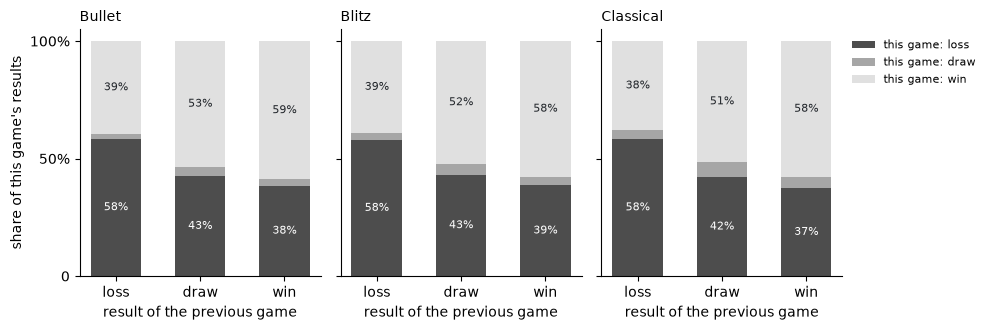

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, tc in zip(axes, CLASSES):
    c = markov.filter(pl.col("speed") == tc)
    bottom = np.zeros(3)
    for cu, shade in zip(R3, ["0.3", "0.65", "0.88"]):
        y = np.array([c.filter(pl.col("prev") == pr, pl.col("cur") == cu)["p"].item() for pr in R3])
        ax.bar(range(3), y, bottom=bottom, width=0.6, color=shade, label=f"this game: {cu}")
        for x, (b, h) in enumerate(zip(bottom, y)):
            if h > 0.08:
                ax.text(x, b + h / 2, f"{100 * h:.0f}%", ha="center", va="center", fontsize=8, color="white" if cu == "loss" else INK)
        bottom += y
    ax.set_xticks(range(3), R3)
    ax.set_xlabel("result of the previous game")
    ax.set_yticks([0, 0.5, 1], ["0", "50%", "100%"])
    ax.set_title(tc, fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("share of this game's results")
axes[2].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_markov.svg")

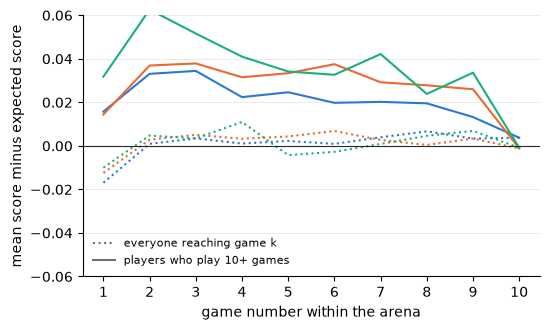

In [16]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for tc in CLASSES:
    for g, ls in [("all", ":"), (f">={KMAX}", "-")]:
        c = seq.filter(pl.col("speed") == tc, pl.col("group") == g).sort("k")
        ax.plot(c["k"], c["resid_mean"], ls, color=COLOR[tc], lw=1.5)
ax.plot([], [], ":", color=MUTE, label="everyone reaching game k")
ax.plot([], [], "-", color=MUTE, label=f"players who play {KMAX}+ games")
ax.set_xticks(range(1, KMAX + 1))
ax.set_xlabel("game number within the arena")
ax.set_ylabel("mean score minus expected score")
ax.set_ylim(-0.06, 0.06)
ax.axhline(0, color=INK, lw=0.8)
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_seq.svg")

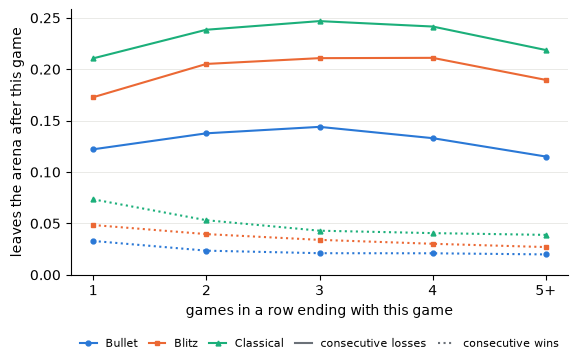

In [17]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for tc in CLASSES:
    for r, ls in [("loss", "-"), ("win", ":")]:
        c = leave.filter(pl.col("speed") == tc, pl.col("result") == r).sort("streak")
        ax.plot(c["streak"], c["leave_rate"], ls, marker=MARK[tc], ms=3.5, color=COLOR[tc], lw=1.5, label=tc if r == "loss" else None)
ax.plot([], [], "-", color=MUTE, label="consecutive losses")
ax.plot([], [], ":", color=MUTE, label="consecutive wins")
ax.set_xticks(range(1, SMAX + 1), [str(k) for k in range(1, SMAX)] + [f"{SMAX}+"])
ax.set_xlabel("games in a row ending with this game")
ax.set_ylim(0, None)
ax.set_ylabel("leaves the arena after this game")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.2), handlelength=1.5, columnspacing=1)
fig.tight_layout()
fig.savefig("outputs/figures/descriptive_slides_streak_leave.svg")